In [2]:
import pandas as pd

# Load data
df = pd.read_csv("amazon_cells_labelled.txt", delimiter="\t", header=None, names=["sentence", "label"])

# Show first few rows
df.head()


,sentence,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [5]:
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Lowercase
    text = text.lower()

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Tokenize
    tokens = tokens = text.split()

    # Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]

    return ' '.join(tokens)

# Apply preprocessing
df['cleaned'] = df['sentence'].apply(preprocess_text)
df.head()


,sentence,label,cleaned
0,So there is no way for me to plug it in here i...,0,way plug u unless go converter
1,"Good case, Excellent value.",1,good case excellent value
2,Great for the jawbone.,1,great jawbone
3,Tied to charger for conversations lasting more...,0,tied charger conversation lasting 45 minutesma...
4,The mic is great.,1,mic great


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['cleaned'])  # features
y = df['label']                              # labels
print(y.head())



0    0
1    1
2    1
3    0
4    1
Name: label, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
_ = lr_model.fit(X_train, y_train)


In [11]:
print("Naive Bayes Performance:")
print(classification_report(y_test, nb_preds))

print("Logistic Regression Performance:")
print(classification_report(y_test, lr_preds))


Naive Bayes Performance:
              precision    recall  f1-score   support

           0       0.80      0.75      0.78        93
           1       0.80      0.84      0.82       107

    accuracy                           0.80       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.80      0.80       200

Logistic Regression Performance:
              precision    recall  f1-score   support

           0       0.72      0.84      0.77        93
           1       0.84      0.71      0.77       107

    accuracy                           0.77       200
   macro avg       0.78      0.77      0.77       200
weighted avg       0.78      0.77      0.77       200



In [9]:
new_review = ["this phone is amazing and works perfectly"]
new_review_cleaned = [preprocess_text(new_review[0])]
new_vector = vectorizer.transform(new_review_cleaned)
result = nb_model.predict(new_vector)  # outputs 1 or 0
print(result[0])

1


In [10]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Predictions
nb_preds = nb_model.predict(X_test)
lr_preds = lr_model.predict(X_test)

# Naive Bayes Evaluation
print("Naive Bayes Evaluation:")
print(classification_report(y_test, nb_preds))
print("Confusion Matrix:\n", confusion_matrix(y_test, nb_preds))
print("Accuracy:", accuracy_score(y_test, nb_preds))

# Logistic Regression Evaluation
print("\nLogistic Regression Evaluation:")
print(classification_report(y_test, lr_preds))
print("Confusion Matrix:\n", confusion_matrix(y_test, lr_preds))
print("Accuracy:", accuracy_score(y_test, lr_preds))


Naive Bayes Evaluation:
              precision    recall  f1-score   support

           0       0.80      0.75      0.78        93
           1       0.80      0.84      0.82       107

    accuracy                           0.80       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.80      0.80       200

Confusion Matrix:
 [[70 23]
 [17 90]]
Accuracy: 0.8

Logistic Regression Evaluation:
              precision    recall  f1-score   support

           0       0.72      0.84      0.77        93
           1       0.84      0.71      0.77       107

    accuracy                           0.77       200
   macro avg       0.78      0.77      0.77       200
weighted avg       0.78      0.77      0.77       200

Confusion Matrix:
 [[78 15]
 [31 76]]
Accuracy: 0.77


In [15]:
# Function to predict sentiment from a raw sentence
def predict_sentiment(text):
    # Step 1: Preprocess
    cleaned = preprocess_text(text)
    
    # Step 2: Vectorize using previously trained TF-IDF
    vectorized = vectorizer.transform([cleaned])
    
    # Step 3: Predict using both models
    nb_result = nb_model.predict(vectorized)[0]
    lr_result = lr_model.predict(vectorized)[0]
    
    print(f"\nInput: {text}")
    print(f"Naive Bayes Prediction: {'Positive' if nb_result == 1 else 'Negative'}")
    print(f"Logistic Regression Prediction: {'Positive' if lr_result == 1 else 'Negative'}")

# Example usage
predict_sentiment("I am very happy with this purchase")
predict_sentiment("Not satisfied at all")
predict_sentiment("I have no complaints")



Input: I am very happy with this purchase
Naive Bayes Prediction: Positive
Logistic Regression Prediction: Positive

Input: Not satisfied at all
Naive Bayes Prediction: Positive
Logistic Regression Prediction: Positive

Input: I have no complaints
Naive Bayes Prediction: Negative
Logistic Regression Prediction: Negative


Class Distribution:
 label
0    500
1    500
Name: count, dtype: int64


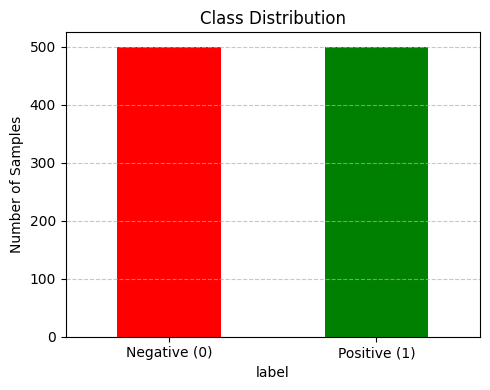

In [16]:
import matplotlib.pyplot as plt

# Count the labels
label_counts = df['label'].value_counts()
print("Class Distribution:\n", label_counts)

# Plot it
plt.figure(figsize=(5,4))
label_counts.plot(kind='bar', color=['red', 'green'])
plt.title('Class Distribution')
plt.xticks(ticks=[0, 1], labels=['Negative (0)', 'Positive (1)'], rotation=0)
plt.ylabel('Number of Samples')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [19]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Initialize the sentiment analyzer
vader = SentimentIntensityAnalyzer()


In [20]:
# Get original (non-cleaned) test sentences
test_sentences = df.iloc[y_test.index]['sentence']

# Get VADER predictions
vader_preds = []

for sentence in test_sentences:
    score = vader.polarity_scores(sentence)
    compound = score['compound']
    vader_preds.append(1 if compound >= 0 else 0)  # 1 = Positive, 0 = Negative

# Evaluate
from sklearn.metrics import classification_report, accuracy_score

print("VADER Sentiment Analysis Evaluation:")
print(classification_report(y_test, vader_preds))
print("Accuracy:", accuracy_score(y_test, vader_preds))


VADER Sentiment Analysis Evaluation:
              precision    recall  f1-score   support

           0       0.93      0.60      0.73        93
           1       0.74      0.96      0.83       107

    accuracy                           0.80       200
   macro avg       0.83      0.78      0.78       200
weighted avg       0.83      0.80      0.79       200

Accuracy: 0.795


In [21]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt


In [22]:
# Separate reviews by label
positive_reviews = df[df['label'] == 1]['cleaned']
negative_reviews = df[df['label'] == 0]['cleaned']

# Combine into single strings
positive_text = ' '.join(positive_reviews)
negative_text = ' '.join(negative_reviews)


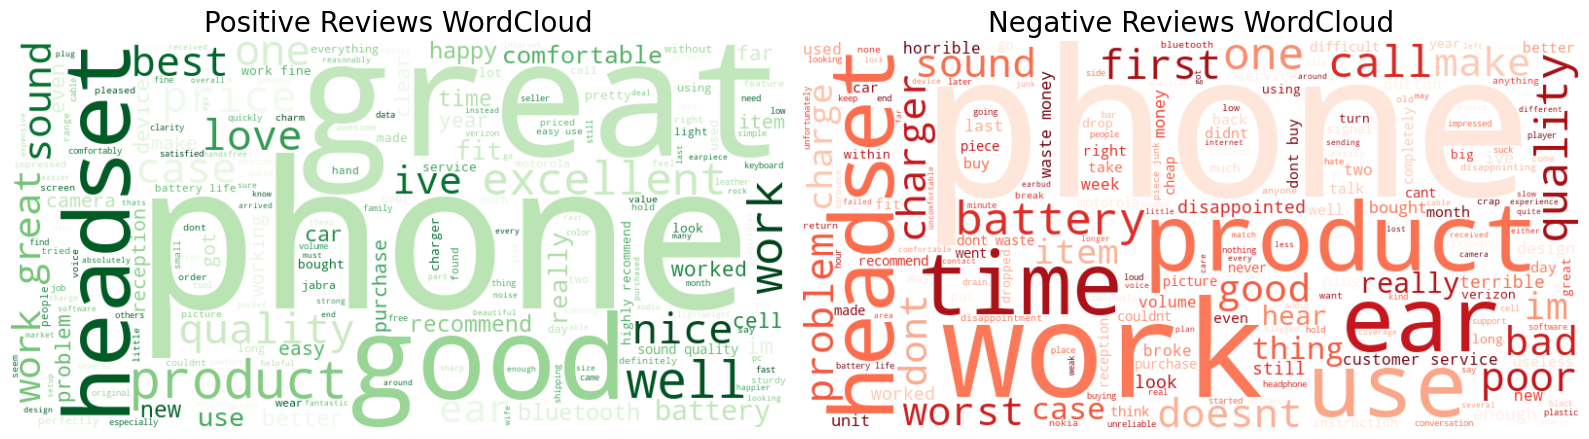

In [23]:
# Positive WordCloud
wordcloud_pos = WordCloud(width=800, height=400, background_color='white', colormap='Greens').generate(positive_text)

# Negative WordCloud
wordcloud_neg = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(negative_text)

# Display side-by-side
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.title("Positive Reviews WordCloud", fontsize=20)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.title("Negative Reviews WordCloud", fontsize=20)
plt.axis('off')

plt.tight_layout()
plt.show()
